In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Circle
from matplotlib.colors import LinearSegmentedColormap



running steady (low Re) case...
running unstable (high Re) case...
rendering 65 frames...
saved: steady_vs_unstable.gif


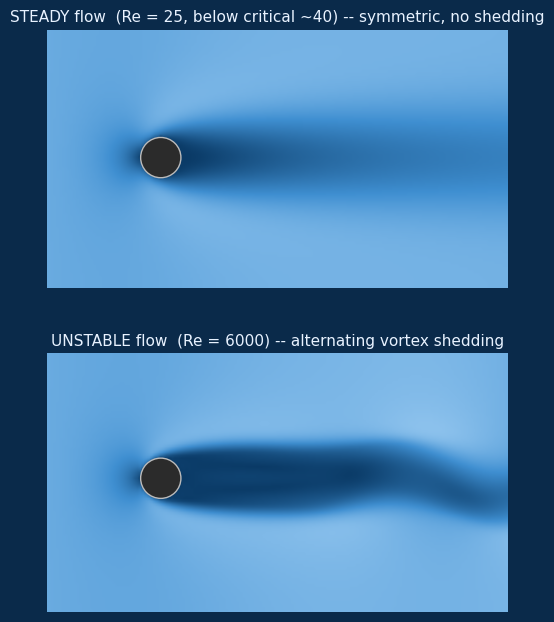

In [3]:
Nx, Ny = 160, 90
SX, SY = Nx + 2, Ny + 2
D = 14.0
cx, cy_steady = 40.0, Ny / 2 + 1.0
cy_unstable = Ny / 2 + 2.0

U_in = 1.0
dt = 0.5
GS_ITERS = 26

FRAME_INTERVAL = 10   # capture a frame every N simulation steps
N_STEPS = 650         # run both cases this long (steady settles early and just holds)
OUT_GIF = "steady_vs_unstable.gif"

xx, yy = np.meshgrid(np.arange(SX), np.arange(SY), indexing='ij')


def set_bnd_vel(u, v):
    u[0, :] = U_in; v[0, :] = 0.0; u[-1, :] = u[-2, :]; v[-1, :] = v[-2, :]
    v[:, 0] = 0.0; v[:, -1] = 0.0; u[:, 0] = u[:, 1]; u[:, -1] = u[:, -2]


def set_bnd_pressure(p):
    p[0, :] = p[1, :]; p[-1, :] = 0.0; p[:, 0] = p[:, 1]; p[:, -1] = p[:, -2]


def diffuse_component(x, x0, diff_rate, dt, is_u, iters=GS_ITERS):
    a = dt * diff_rate; c_inv = 1.0 / (1 + 4 * a)
    for _ in range(iters):
        x[1:-1, 1:-1] = (x0[1:-1, 1:-1] + a * (x[0:-2, 1:-1] + x[2:, 1:-1] + x[1:-1, 0:-2] + x[1:-1, 2:])) * c_inv
        if is_u:
            x[0, :] = U_in; x[-1, :] = x[-2, :]; x[:, 0] = x[:, 1]; x[:, -1] = x[:, -2]
        else:
            x[0, :] = 0.0; x[-1, :] = x[-2, :]; x[:, 0] = 0.0; x[:, -1] = 0.0
    return x


def advect(d, d0, u, v, dt, is_u):
    Xg, Yg = np.meshgrid(np.arange(1, Nx + 1), np.arange(1, Ny + 1), indexing='ij')
    x = Xg - dt * u[1:-1, 1:-1]; y = Yg - dt * v[1:-1, 1:-1]
    x = np.clip(x, 0.5, Nx + 0.5); y = np.clip(y, 0.5, Ny + 0.5)
    i0 = x.astype(int); i1 = i0 + 1; j0 = y.astype(int); j1 = j0 + 1
    s1 = x - i0; s0 = 1 - s1; t1 = y - j0; t0 = 1 - t1
    d[1:-1, 1:-1] = (s0 * (t0 * d0[i0, j0] + t1 * d0[i0, j1]) + s1 * (t0 * d0[i1, j0] + t1 * d0[i1, j1]))
    if is_u:
        d[0, :] = U_in; d[-1, :] = d[-2, :]; d[:, 0] = d[:, 1]; d[:, -1] = d[:, -2]
    else:
        d[0, :] = 0.0; d[-1, :] = d[-2, :]; d[:, 0] = 0.0; d[:, -1] = 0.0
    return d


def project(u, v, p, div):
    div[1:-1, 1:-1] = -0.5 * (u[2:, 1:-1] - u[0:-2, 1:-1] + v[1:-1, 2:] - v[1:-1, 0:-2])
    p[:] = 0
    set_bnd_pressure(div); set_bnd_pressure(p)
    for _ in range(GS_ITERS):
        p[1:-1, 1:-1] = (div[1:-1, 1:-1] + p[0:-2, 1:-1] + p[2:, 1:-1] + p[1:-1, 0:-2] + p[1:-1, 2:]) / 4.0
        set_bnd_pressure(p)
    u[1:-1, 1:-1] -= 0.5 * (p[2:, 1:-1] - p[0:-2, 1:-1])
    v[1:-1, 1:-1] -= 0.5 * (p[1:-1, 2:] - p[1:-1, 0:-2])
    set_bnd_vel(u, v)
    return u, v


def run_case(Re, cy, seed, n_steps, frame_interval):
    """Same physics as before, but now returns a LIST of speed fields
    (one every `frame_interval` steps) instead of just the final one."""
    nu = U_in * D / Re
    mask = (xx - cx) ** 2 + (yy - cy) ** 2 <= (D / 2) ** 2
    u = np.full((SX, SY), U_in); v = np.zeros((SX, SY)); u[mask] = 0.0
    frames = []
    for step in range(n_steps):
        u0 = u.copy(); v0 = v.copy()
        diffuse_component(u, u0, nu, dt, True)
        diffuse_component(v, v0, nu, dt, False)
        p = np.zeros((SX, SY)); div = np.zeros((SX, SY))
        project(u, v, p, div); u[mask] = 0.0; v[mask] = 0.0
        u0 = u.copy(); v0 = v.copy()
        advect(u, u0, u0, v0, dt, True); advect(v, v0, u0, v0, dt, False)
        project(u, v, p, div); u[mask] = 0.0; v[mask] = 0.0
        if seed and step < 8:
            v[int(cx) + 3:int(cx) + 8, Ny // 2:Ny // 2 + 2] += 0.3

        if step % frame_interval == 0:
            speed = np.sqrt(u[1:-1, 1:-1] ** 2 + v[1:-1, 1:-1] ** 2)
            frames.append(speed.copy())
    return frames


print("running steady (low Re) case...")
frames_steady = run_case(Re=25, cy=cy_steady, seed=False, n_steps=N_STEPS, frame_interval=FRAME_INTERVAL)
print("running unstable (high Re) case...")
frames_unstable = run_case(Re=6000, cy=cy_unstable, seed=True, n_steps=N_STEPS, frame_interval=FRAME_INTERVAL)

n_frames = min(len(frames_steady), len(frames_unstable))
print(f"rendering {n_frames} frames...")

water_cmap = LinearSegmentedColormap.from_list("plain_water", ["#0a3a66", "#3f8fd1", "#bfe3ff"])

fig, axes = plt.subplots(2, 1, figsize=(9, 6.4), facecolor="#0a2a4a")

ims = []
for ax, cy_, title in [
    (axes[0], cy_steady, "STEADY flow  (Re = 25, below critical ~40) -- symmetric, no shedding"),
    (axes[1], cy_unstable, "UNSTABLE flow  (Re = 6000) -- alternating vortex shedding"),
]:
    ax.set_facecolor("#0a2a4a")
    ax.axis("off")
    ax.set_title(title, color="#e8f2ff", fontsize=11)
    im = ax.imshow(np.transpose(frames_steady[0], (1, 0)), origin="lower", cmap=water_cmap,
                    vmin=0, vmax=1.5, interpolation="bilinear")
    ax.add_patch(Circle((cx - 1, cy_ - 1), D / 2, facecolor="#2b2b2b", edgecolor="#bbbbbb", linewidth=1, zorder=3))
    ims.append(im)

fig.subplots_adjust(left=0.02, right=0.98, top=0.93, bottom=0.02, hspace=0.25)


def update(i):
    ims[0].set_data(np.transpose(frames_steady[i], (1, 0)))
    ims[1].set_data(np.transpose(frames_unstable[i], (1, 0)))
    return ims


anim = animation.FuncAnimation(fig, update, frames=n_frames, blit=True)
anim.save(OUT_GIF, writer=animation.PillowWriter(fps=20), dpi=120,
          savefig_kwargs={"facecolor": fig.get_facecolor()})
print("saved:", OUT_GIF)